In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

vix = pd.read_excel("VIX Monthly.xlsx")

In [24]:
vix.columns = ["date", "vix"]

vix["date"] = pd.to_datetime(vix["date"], dayfirst=True)

vix = vix.sort_values("date")

In [25]:
vix.head()

,date,vix
0,2015-11-30,16.13
1,2015-12-31,18.21
2,2016-01-29,20.20
3,2016-02-29,20.55
4,2016-03-31,13.95


In [26]:
vix["log_vix"] = np.log(vix["vix"])

vix["dlog_vix"] = vix["log_vix"] - vix["log_vix"].shift(1)

In [27]:
vix = vix.dropna()

In [28]:
vix = vix[vix["date"] >= "2015-12-29"]

In [29]:
vix.shape
vix.head()
vix["dlog_vix"].describe()

count    121.000000
mean      -0.000628
std        0.231847
min       -0.614279
25%       -0.133878
50%       -0.004412
75%        0.121290
max        0.755643
Name: dlog_vix, dtype: float64

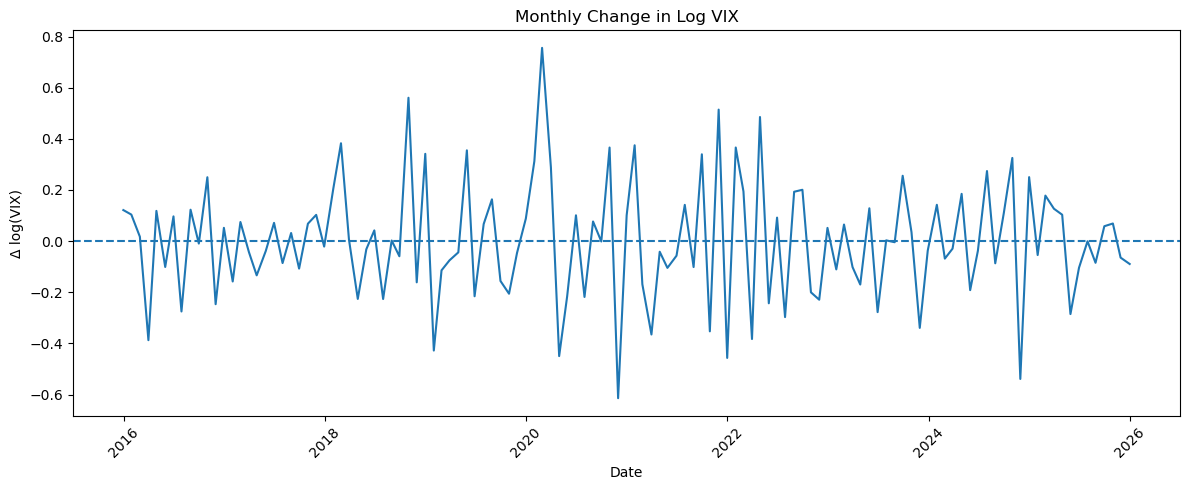

In [30]:
plt.figure(figsize=(12,5))

plt.plot(vix["date"], vix["dlog_vix"])
plt.axhline(0, linestyle="--")

plt.title("Monthly Change in Log VIX")
plt.xlabel("Date")
plt.ylabel("Δ log(VIX)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [31]:
vix = vix.copy()
vix["date"] = pd.to_datetime(vix["date"])
vix["date"] = vix["date"] + pd.offsets.MonthEnd(0)

In [32]:
vix.head()

,date,vix,log_vix,dlog_vix
1,2015-12-31,18.21,2.901971,0.121290
2,2016-01-31,20.20,3.005683,0.103712
3,2016-02-29,20.55,3.022861,0.017178
4,2016-03-31,13.95,2.635480,-0.387381
5,2016-04-30,15.70,2.753661,0.118181


In [33]:
vix_final = vix[["date", "dlog_vix"]].copy()
vix_final = vix_final.sort_values("date")

vix_final.to_csv("vix_clean.csv", index=False)